# Student Clustering with K-Means

This notebook uses `data/student_clustering.csv`: 500 students. There is no pass/fail column.

Clustering is unsupervised. The model is not given a label to predict. It only sees study hours, attendance, and assignment score, and it groups students who look alike on those three numbers.

The steps are:

1. Look at the table and drop any missing values or duplicate rows.
2. Plot the students. Separate clouds, and no label column, mean the task is clustering.
3. Scale the three features so each one counts equally.
4. Use the elbow curve to choose the number of clusters.
5. Fit k-means with that number.
6. Check the fit with the silhouette score and the cluster centers.
7. Plot the students again, with each cluster in its own color.


In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Keep the plots in the notebook, and use the same grid style as the other demos.
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
%matplotlib inline


## Load the data

`Student_ID` only identifies a row. The three numeric columns are the inputs. There is no target column, because a clustering model does not predict a known answer.


In [2]:
# The notebook lives in Demo/, so the CSV is one folder up.
# The second path is a fallback if this cell is run from the project root.
path = Path("../data/student_clustering.csv")
if not path.exists():
    path = Path("data/student_clustering.csv")

students = pd.read_csv(path)

print("Rows and columns:", students.shape)
students.head()


Rows and columns: (500, 4)


,Student_ID,Study_Hours,Attendance,Assignment_Score
0,S001,7.5,64,92
1,S002,7.4,91,87
2,S003,6.5,64,91
3,S004,1.7,58,52
4,S005,2.4,57,40


## Remove missing values and duplicate rows

A blank cell cannot be used, because k-means needs a number in every column. A repeated row would be counted twice, so that student would pull a cluster center toward them. Drop those rows if they are in the file. If the file is already clean, the table stays the same.


In [3]:
print("Missing values before:")
print(students.isna().sum())
print("Duplicate rows before:", int(students.duplicated().sum()))

rows_before = len(students)
students = students.drop_duplicates()
students = students.dropna().reset_index(drop=True)

print()
print("Rows before:", rows_before)
print("Rows after:", len(students))
print("Missing values left:", int(students.isna().sum().sum()))
print("Duplicate rows left:", int(students.duplicated().sum()))


Missing values before:
Student_ID          0
Study_Hours         0
Attendance          0
Assignment_Score    0
dtype: int64
Duplicate rows before: 0

Rows before: 500
Rows after: 500
Missing values left: 0
Duplicate rows left: 0


## Exploratory check

The summary shows how wide each feature is. The scatter plots then show whether the students sit in one cloud or in a few separate clouds.

There is still no column that says which group a student belongs to. If the dots form separate clouds, the job is to find those groups. That is clustering.


In [4]:
print(students.dtypes)
print()
students[["Study_Hours", "Attendance", "Assignment_Score"]].describe()


Student_ID           object
Study_Hours         float64
Attendance            int64
Assignment_Score      int64
dtype: object



,Study_Hours,Attendance,Assignment_Score
count,500.000000,500.000000,500.000000
mean,5.685200,70.024000,71.474000
std,2.587588,14.903276,19.874187
min,0.600000,40.000000,30.000000
25%,2.800000,58.750000,49.000000
50%,6.500000,64.000000,81.000000
75%,7.900000,87.000000,87.000000
max,10.000000,100.000000,100.000000


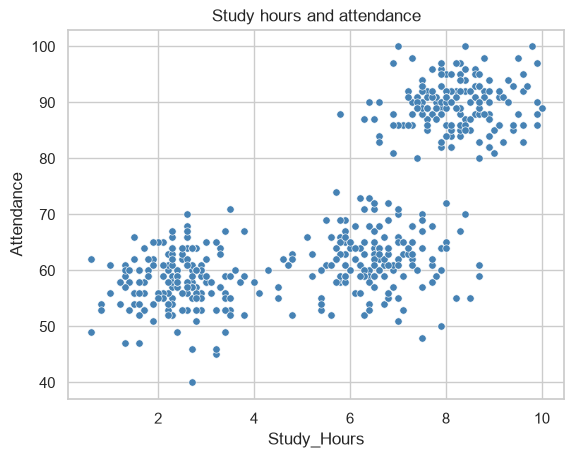

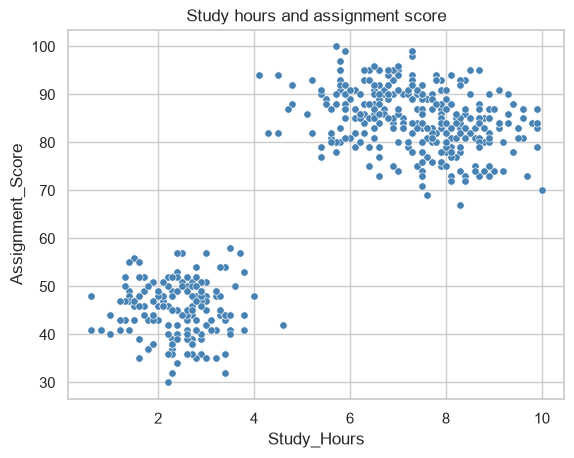

In [5]:
# Each dot is one student. Separate clouds mean the students already
# fall into groups, even though the file has no group label.
sns.scatterplot(data=students, x="Study_Hours", y="Attendance", color="steelblue", s=28)
plt.title("Study hours and attendance")
plt.show()

sns.scatterplot(data=students, x="Study_Hours", y="Assignment_Score", color="steelblue", s=28)
plt.title("Study hours and assignment score")
plt.show()


The dots are not one even cloud. Study hours against attendance, and study hours against assignment score, both show a few separate groups. The file has no label to predict, so the next step is k-means clustering, not classification.


## Scale the features

`Student_ID` is not a feature. The other three columns are the only inputs. Every cleaned row is used. There is no train/test split and no label.

K-means groups points by distance. Study hours run from about 1 to 10, while attendance runs from about 40 to 100. Without scaling, attendance would dominate the distance and study hours would barely matter. `StandardScaler` puts each column on a similar scale before the distances are computed.


In [6]:
feature_columns = ["Study_Hours", "Attendance", "Assignment_Score"]
X = students[feature_columns]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Rows used for clustering:", X_scaled.shape[0])
print("Features:", X_scaled.shape[1])


Rows used for clustering: 500
Features: 3


## Elbow curve

K-means needs k, the number of groups, before it starts. That number is not in the file.

Inertia is how far the students sit from their own cluster center. It always falls as k grows, because smaller groups fit more tightly. The useful point is the elbow: the bend where extra clusters stop helping much. That bend is the k to use.


1 1500.0
2 462.0
3 137.1
4 124.2
5 113.1
6 101.9
7 95.4
8 88.4


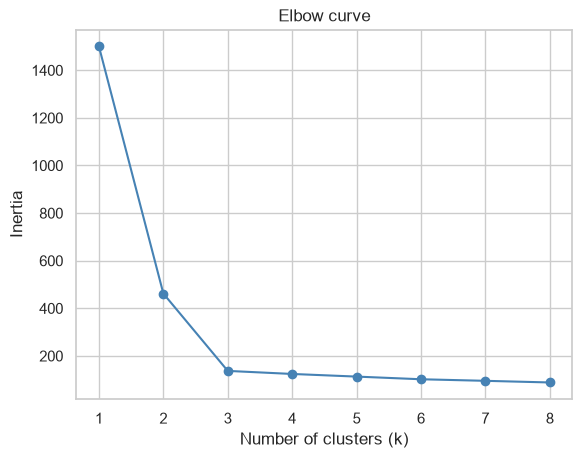

In [7]:
# Fit k-means once for each k and keep the inertia.
ks = range(1, 9)
inertias = []

for k in ks:
    trial = KMeans(n_clusters=k, n_init=10, random_state=42)
    trial.fit(X_scaled)
    inertias.append(trial.inertia_)

for k, inertia in zip(ks, inertias):
    print(k, round(inertia, 1))

plt.plot(list(ks), inertias, marker="o", color="steelblue")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow curve")
plt.xticks(list(ks))
plt.show()


The line drops sharply until k = 3, then flattens. Three is the number of clusters.


## Fit k-means

K-means places 3 centers, assigns every student to the nearest center, then moves each center to the middle of its students. It repeats those two steps until the centers stop moving.

The cluster numbers (0, 1, 2) are only ids. They do not mean "better" or "worse" until the centers are read in the original units.


In [8]:
k = 3
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
students["Cluster"] = kmeans.fit_predict(X_scaled)

print("Students in each cluster:")
print(students["Cluster"].value_counts().sort_index())


Students in each cluster:
Cluster
0    160
1    170
2    170
Name: count, dtype: int64


## Evaluation

Two checks on the fitted model:

- **Silhouette score** runs from -1 to 1. A score near 1 means students are close to their own group and far from the other groups.
- **Cluster centers** are the average student in each group, turned back into study hours, attendance, and assignment score. A useful clustering has a different kind of student in each row.


In [9]:
score = silhouette_score(X_scaled, students["Cluster"])
print("Silhouette score:", round(score, 3))

# The model was fit on scaled columns. inverse_transform puts the
# centers back into hours, attendance percent, and assignment points.
centers = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=feature_columns,
)
centers.insert(0, "Cluster", range(k))
centers = centers.round(2)

print()
print("Cluster centers:")
centers


Silhouette score: 0.692

Cluster centers:


,Cluster,Study_Hours,Attendance,Assignment_Score
0,0,6.51,61.98,88.02
1,1,2.40,58.05,45.08
2,2,8.20,89.56,82.30


## Clusters on a scatter plot

The same two views as the exploratory plots, now colored by the cluster k-means assigned. Each color is one group.


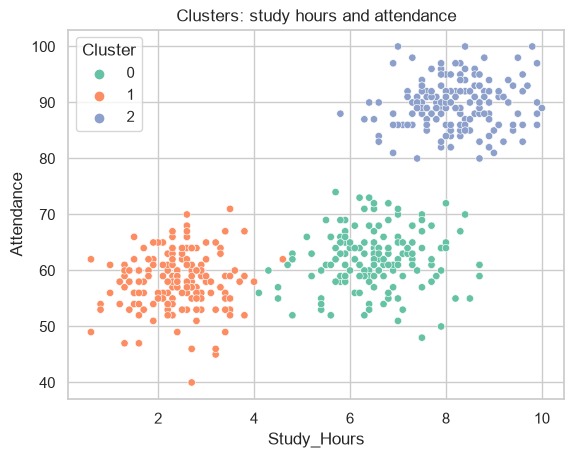

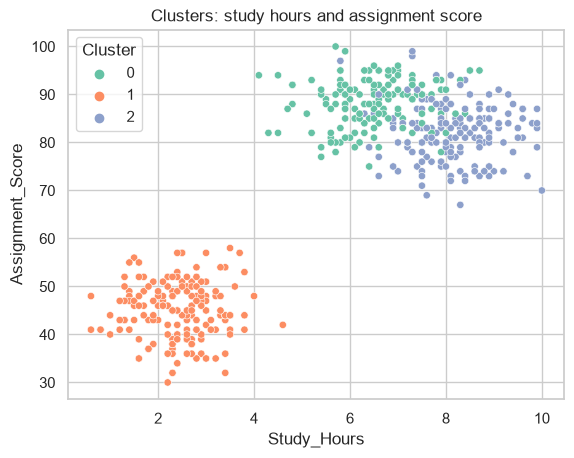

In [10]:
sns.scatterplot(
    data=students,
    x="Study_Hours",
    y="Attendance",
    hue="Cluster",
    palette="Set2",
    s=28,
)
plt.title("Clusters: study hours and attendance")
plt.show()

sns.scatterplot(
    data=students,
    x="Study_Hours",
    y="Assignment_Score",
    hue="Cluster",
    palette="Set2",
    s=28,
)
plt.title("Clusters: study hours and assignment score")
plt.show()


## Takeaways

The elbow bends at 3, so the model is fit with 3 clusters. The silhouette score is about 0.69, which means the groups are cleanly separated.

Reading the centers in the original units gives three kinds of student:

- One group is low on study hours, attendance, and assignment score.
- One group is high on all three.
- One group has strong assignment scores and solid study hours, but much lower attendance.

The cluster id attached to each kind of student can change if the model is restarted with a different `random_state`. The three patterns are what the evaluation is for, not the particular numbers 0, 1, and 2.
